# 10 – Urban Atlas vs baseline clusters

**Goal:** compare the current best clustering (300 m radius features, k = 6, `clusters_radius.csv`) with the
Copernicus **Urban Atlas 2021** land use / land cover map, side by side.

**Role of Urban Atlas:** reference for comparison ONLY, never an input (circularity rule; Urban Atlas was dropped
as an input in Oct 2026 because its classes are predefined categories). The question here: where do our clusters
agree with an official land-use map, and where do they split or merge its classes?

- **Input:** `data/raw/Urban Atlas/CLMS_UA_LCU_S2021_..._SI001L2_LJUBLJANA_....fgb` (EPSG:3035, Ljubljana functional urban area),
  `data/processed/cells.gpkg`, `clusters_radius.csv`
- **Output:** `data/processed/ua_cells.csv` (dominant UA class per cell), `figures/10_urban_atlas_vs_clusters.png`, `figures/10_crosstab.png`

**Method:**
1. Reproject Urban Atlas to EPSG:3794 and clip it to MOL.
2. Intersect it with the 100 m grid; for each cell take the class that covers the **largest area** (dominant class) and its share.
3. Group the 27 UA classes into 10 broad groups (27 colours would be unreadable).
4. Maps side by side, with the **same colour for analogous categories** (forest = green in both, ...).
5. Crosstab: for each cluster, which UA groups its cells fall into. ARI / NMI as a single agreement number.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

UA_NAME = "CLMS_UA_LCU_S2021_V025ha_SI001L2_LJUBLJANA_03035_V01_R00_20240809"
UA_FILE = RAW / "Urban Atlas" / UA_NAME / f"{UA_NAME}.fgb"
MOL_FILE = RAW / "LJ_prebivalstvo_MOL_100m_2025" / "obcina_ljubljana.gpkg"
CRS = "EPSG:3794"

## 1. Load and check the clusters
Quick profile to confirm which cluster number is which (names from notebook 07).

In [2]:
cells_gdf = gpd.read_file(PROCESSED / "cells.gpkg")
clusters = pd.read_csv(PROCESSED / "clusters_radius.csv", usecols=["cell_id", "cluster"])
bld = pd.read_csv(PROCESSED / "ind_buildings.csv")
lc = pd.read_csv(PROCESSED / "ind_land_cover.csv")
rad = pd.read_csv(PROCESSED / "ind_radius.csv")

chk = (clusters.merge(cells_gdf[["cell_id", "pop"]], on="cell_id")
       .merge(lc[["cell_id", "imp_share", "can_cover"]], on="cell_id")
       .merge(bld[["cell_id", "bld_height", "bld_residential_share"]], on="cell_id")
       .merge(rad[["cell_id", "poi_r300"]], on="cell_id"))
g = chk.groupby("cluster")
pd.DataFrame({"cells": g.size(), "residents": g["pop"].sum().round(0),
              "imp_share": g["imp_share"].median(), "can_cover": g["can_cover"].median(),
              "bld_height": g["bld_height"].median(), "residential_share": g["bld_residential_share"].median(),
              "poi_r300 (mean)": g["poi_r300"].mean()}).round(2)

C:\Users\Maks\miniforge3\envs\urban\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


,cells,residents,imp_share,can_cover,bld_height,residential_share,poi_r300 (mean)
cluster,,,,,,,
0,11331,135.0,0.00,0.96,0.00,0.00,0.01
1,8395,125.0,0.00,0.08,0.00,0.00,0.02
2,3103,33918.0,0.17,0.10,7.45,0.79,0.07
3,2670,204338.0,0.53,0.08,8.59,0.87,0.33
4,1376,417.0,0.74,0.04,9.44,0.00,0.35
5,590,61493.0,0.73,0.10,17.76,0.61,2.21


In [3]:
CLUSTER_NAMES = {
    0: "forest",
    1: "open land",
    2: "sparse residential / villages",
    3: "urban residential",
    4: "non-residential",
    5: "centre / mixed",
}
# Colours shared with the Urban Atlas map for analogous categories (palette checked with the dataviz validator;
# dark grey for non-residential is a deliberate neutral, the usual map convention for industry)
CLUSTER_COLORS = {
    0: "#008300",  # forest
    1: "#eda100",  # open land
    2: "#b88be8",  # sparse residential
    3: "#2a78d6",  # urban residential
    4: "#4a4a4a",  # non-residential
    5: "#e34948",  # centre / mixed
}

## 2. Urban Atlas → dominant class per cell
Urban Atlas covers the whole functional urban area (much larger than MOL), so we clip first.
Polygons are digitised from 2–4 m imagery with a minimum mapping unit of 0.25 ha in urban areas, so one 100 m cell
(1 ha) often contains several polygons → we keep the class with the largest area in the cell.

In [4]:
ua = gpd.read_file(UA_FILE).to_crs(CRS)
mol = gpd.read_file(MOL_FILE).to_crs(CRS)
ua = gpd.clip(ua, mol)[["code_2021", "class_2021", "geometry"]]
print(f"Polygons in MOL: {len(ua):,}  |  area {ua.area.sum() / 1e4:,.0f} ha  (MOL {mol.area.sum() / 1e4:,.0f} ha)")

pieces = gpd.overlay(cells_gdf[["cell_id", "geometry"]], ua, how="intersection", keep_geom_type=True)
pieces["area"] = pieces.area
by_class = pieces.groupby(["cell_id", "code_2021", "class_2021"], as_index=False)["area"].sum()
by_class["share"] = by_class["area"] / by_class.groupby("cell_id")["area"].transform("sum")
dominant = by_class.sort_values("share", ascending=False).drop_duplicates("cell_id")
dominant = dominant.rename(columns={"code_2021": "ua_code", "class_2021": "ua_class", "share": "ua_share"})
print(f"Cells with a UA class: {len(dominant):,} of {len(cells_gdf):,}")
print(f"Dominant class covers on average {dominant['ua_share'].mean():.0%} of the cell; "
      f"{(dominant['ua_share'] < 0.5).mean():.0%} of cells have no class above 50 %")

Polygons in MOL: 7,618  |  area 27,499 ha  (MOL 27,499 ha)


Cells with a UA class: 27,505 of 27,505
Dominant class covers on average 82% of the cell; 9% of cells have no class above 50 %


### Group the 27 classes
Groups follow the UA hierarchy, except urban fabric, which is split by sealing (S.L. = soil sealing) so that it lines up
with our residential clusters. Each group gets the colour of the cluster it is most *analogous* to; this is a visual aid,
not a claim that they are the same. Groups with no analogous cluster (roads/rail, urban green, construction/mining, water)
get muted colours.

In [5]:
UA_GROUPS = {
    "11100": "continuous urban fabric (>80 %)",
    "11210": "dense / medium urban fabric (30–80 %)", "11220": "dense / medium urban fabric (30–80 %)",
    "11230": "low-density urban fabric, isolated (<30 %)", "11240": "low-density urban fabric, isolated (<30 %)",
    "11300": "low-density urban fabric, isolated (<30 %)",
    "12100": "industrial, commercial, public",
    "12210": "roads and rail", "12220": "roads and rail", "12230": "roads and rail",
    "12300": "roads and rail", "12400": "roads and rail",
    "13100": "mining, construction, unused", "13300": "mining, construction, unused", "13400": "mining, construction, unused",
    "14110": "urban green, sport", "14120": "urban green, sport", "14130": "urban green, sport", "14200": "urban green, sport",
    "21000": "agriculture, grassland", "22000": "agriculture, grassland", "23000": "agriculture, grassland",
    "24000": "agriculture, grassland", "32000": "agriculture, grassland", "33000": "agriculture, grassland",
    "31000": "forest",
    "40000": "water, wetland", "50000": "water, wetland",
}
UA_GROUP_COLORS = {   # order = legend order
    "forest": "#008300",
    "agriculture, grassland": "#eda100",
    "low-density urban fabric, isolated (<30 %)": "#b88be8",
    "dense / medium urban fabric (30–80 %)": "#2a78d6",
    "industrial, commercial, public": "#4a4a4a",
    "continuous urban fabric (>80 %)": "#e34948",
    "urban green, sport": "#a6dba0",
    "roads and rail": "#c8c8c8",
    "mining, construction, unused": "#d9c3a5",
    "water, wetland": "#9ecae1",
}
dominant["ua_code"] = dominant["ua_code"].astype(str)
unknown = dominant.loc[~dominant["ua_code"].isin(UA_GROUPS.keys()), "ua_code"].unique()
assert len(unknown) == 0, unknown
dominant["ua_group"] = dominant["ua_code"].map(UA_GROUPS)
dominant[["cell_id", "ua_code", "ua_class", "ua_group", "ua_share"]].to_csv(PROCESSED / "ua_cells.csv", index=False)
dominant["ua_group"].value_counts()

ua_group
forest                                        11985
agriculture, grassland                         8199
dense / medium urban fabric (30–80 %)          3141
industrial, commercial, public                 2041
urban green, sport                              597
roads and rail                                  541
low-density urban fabric, isolated (<30 %)      452
water, wetland                                  254
continuous urban fabric (>80 %)                 180
mining, construction, unused                    115
Name: count, dtype: int64

## 3. Side-by-side maps

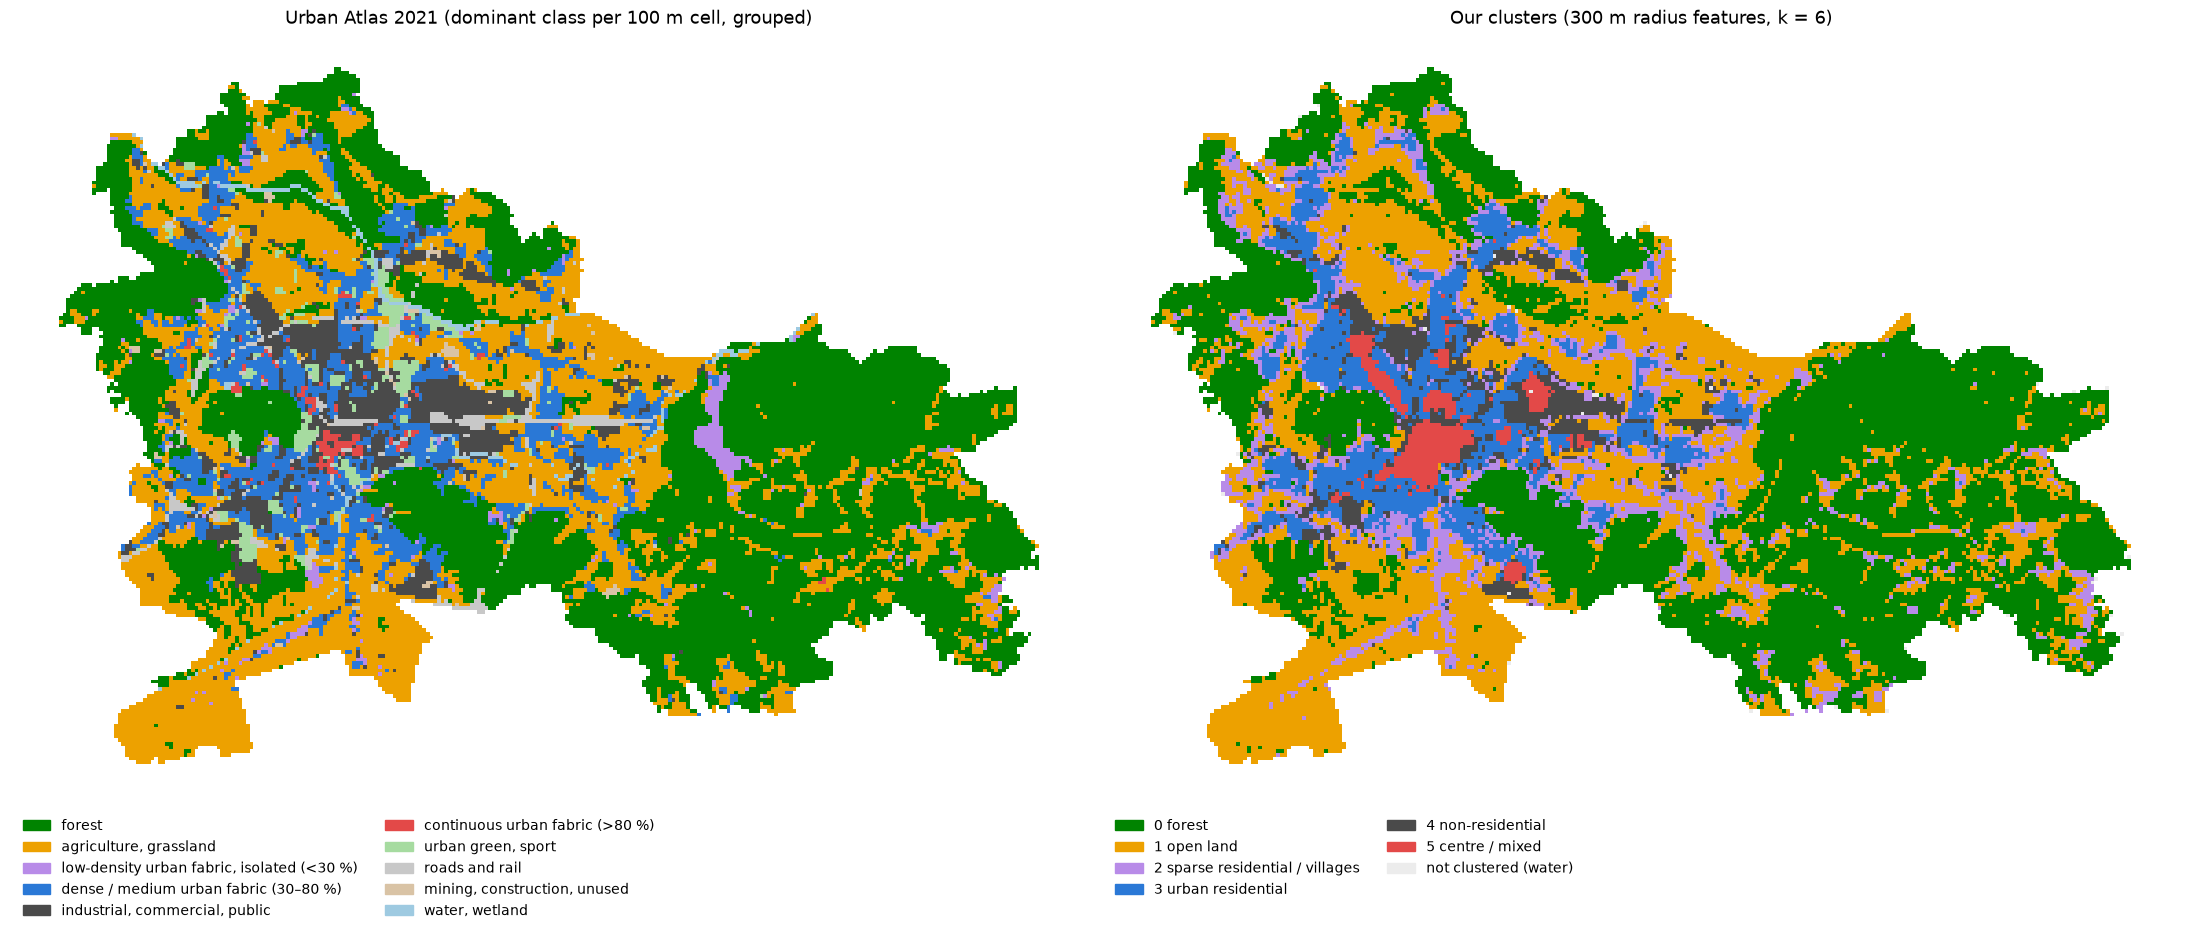

In [6]:
m = (cells_gdf[["cell_id", "geometry"]]
     .merge(clusters, on="cell_id", how="left")
     .merge(dominant[["cell_id", "ua_group"]], on="cell_id", how="left"))

fig, axes = plt.subplots(1, 2, figsize=(22, 9.5))
ax = axes[0]
for grp, col in UA_GROUP_COLORS.items():
    sub = m[m["ua_group"] == grp]
    if len(sub):
        sub.plot(ax=ax, color=col, linewidth=0)
ax.set_title("Urban Atlas 2021 (dominant class per 100 m cell, grouped)", fontsize=13)
ax.legend(handles=[Patch(color=c, label=g_) for g_, c in UA_GROUP_COLORS.items()],
          loc="upper left", bbox_to_anchor=(0, -0.01), ncol=2, frameon=False, fontsize=10)

ax = axes[1]
m[m["cluster"].isna()].plot(ax=ax, color="#ececec", linewidth=0)
for c, col in CLUSTER_COLORS.items():
    m[m["cluster"] == c].plot(ax=ax, color=col, linewidth=0)
ax.set_title("Our clusters (300 m radius features, k = 6)", fontsize=13)
ax.legend(handles=[Patch(color=CLUSTER_COLORS[c], label=f"{c} {CLUSTER_NAMES[c]}") for c in CLUSTER_COLORS]
          + [Patch(color="#ececec", label="not clustered (water)")],
          loc="upper left", bbox_to_anchor=(0, -0.01), ncol=2, frameon=False, fontsize=10)
for ax in axes:
    ax.set_axis_off()
    ax.set_aspect("equal")
plt.tight_layout()
fig.savefig(FIGURES / "10_urban_atlas_vs_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Crosstab and agreement
Each row = one cluster; the numbers are the % of its cells whose dominant UA class falls into each group (rows add up to 100 %).
A "pure" cluster has one dark cell in its row; a cluster spread over several UA groups combines things Urban Atlas keeps apart.

ARI / NMI between two labelings: 1 = identical partition, 0 = no more agreement than chance. Only a rough summary:
the two maps describe different things (UA = land use/cover by visual interpretation; ours = measured form, people, function),
so low agreement is *expected* and not a failure.

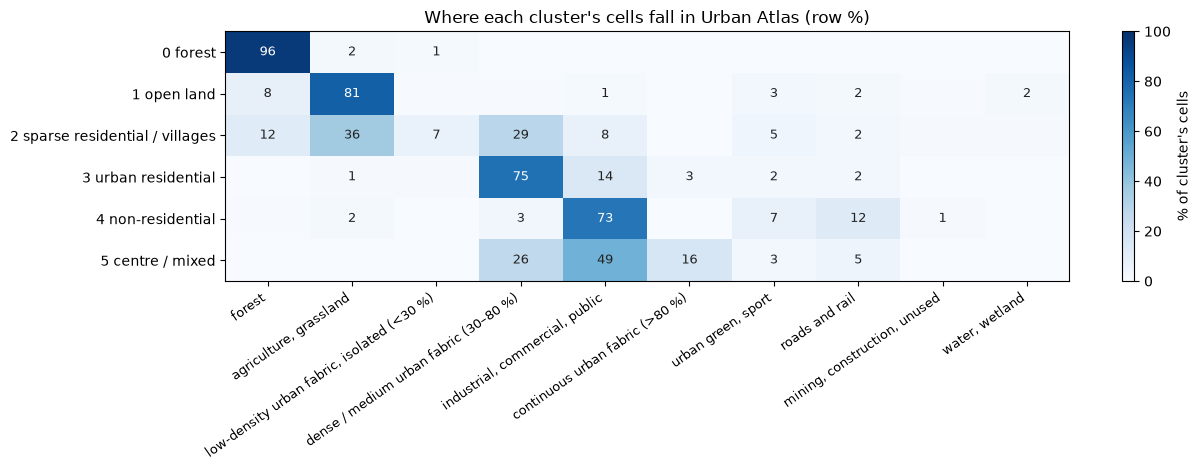

Cells compared: 27,465
ARI  clusters vs UA groups:  0.698
NMI  clusters vs UA groups:  0.552
NMI  clusters vs 27 classes: 0.503
Built-up clusters only (2-5, 7,739 cells): ARI 0.232, NMI 0.277


In [7]:
both = clusters.merge(dominant[["cell_id", "ua_code", "ua_group"]], on="cell_id")
row_label = both["cluster"].map(lambda c: f"{c} {CLUSTER_NAMES[c]}")
ct = pd.crosstab(row_label, both["ua_group"], normalize="index") * 100
ct = ct[[g_ for g_ in UA_GROUP_COLORS if g_ in ct.columns]]

fig, ax = plt.subplots(figsize=(13, 4.8))
im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(ct.shape[1]), ct.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(ct.shape[0]), ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.iloc[i, j]
        if v >= 1:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 55 else "#222222")
fig.colorbar(im, ax=ax, label="% of cluster's cells")
ax.set_title("Where each cluster's cells fall in Urban Atlas (row %)")
plt.tight_layout()
fig.savefig(FIGURES / "10_crosstab.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Cells compared: {len(both):,}")
print(f"ARI  clusters vs UA groups:  {adjusted_rand_score(both['cluster'], both['ua_group']):.3f}")
print(f"NMI  clusters vs UA groups:  {normalized_mutual_info_score(both['cluster'], both['ua_group']):.3f}")
print(f"NMI  clusters vs 27 classes: {normalized_mutual_info_score(both['cluster'], both['ua_code']):.3f}")

# Forest + open land are ~70 % of cells and agree easily, which inflates the overall score -> also built-up clusters only
bu = both[both["cluster"] >= 2]
print(f"Built-up clusters only (2-5, {len(bu):,} cells): ARI {adjusted_rand_score(bu['cluster'], bu['ua_group']):.3f}, "
      f"NMI {normalized_mutual_info_score(bu['cluster'], bu['ua_group']):.3f}")

In [8]:
# The other direction: for each UA group, which clusters its cells go to (% of the UA group's cells)
pd.crosstab(both["ua_group"], row_label, normalize="index").mul(100).round(0)

cluster,0 forest,1 open land,2 sparse residential / villages,3 urban residential,4 non-residential,5 centre / mixed
ua_group,,,,,,
"agriculture, grassland",2.0,83.0,14.0,0.0,0.0,0.0
continuous urban fabric (>80 %),1.0,1.0,3.0,42.0,0.0,53.0
dense / medium urban fabric (30–80 %),0.0,1.0,28.0,64.0,2.0,5.0
forest,91.0,5.0,3.0,0.0,0.0,0.0
"industrial, commercial, public",0.0,6.0,12.0,19.0,49.0,14.0
"low-density urban fabric, isolated (<30 %)",33.0,14.0,46.0,6.0,1.0,0.0
"mining, construction, unused",3.0,52.0,24.0,6.0,13.0,2.0
roads and rail,1.0,36.0,14.0,12.0,31.0,5.0
"urban green, sport",7.0,40.0,24.0,11.0,16.0,3.0


## Summary (1 Nov 2026)
**Data check:** Urban Atlas 2021 for the Ljubljana FUA is complete and correct for MOL: clipped classes add up to
27,499 ha = MOL area, every grid cell gets a class, and the dominant class covers on average 82 % of a cell.

**Where we agree with Urban Atlas (the "easy" land cover):**
- forest cluster: 96 % of its cells are UA forest; open land: 81 % UA agriculture/grassland
- urban residential: 75 % UA dense/medium urban fabric; non-residential: 73 % UA industrial/commercial/public
- overall ARI 0.70 — but this is driven by forest + open land (~70 % of cells).

**Where we differ (inside the city, ARI only ~0.23 on built-up clusters):**
- **Centre / mixed** is a *function* type, which UA does not have: only 16 % of its cells are UA "continuous urban fabric";
  49 % are UA "industrial, commercial, public" (UA puts offices, shops, university, hospitals in the same class as factories)
  and 26 % dense urban fabric. Our POI + height separate the centre from industry; UA does not.
- **Non-residential** also absorbs roads/rail (12 %) and urban green/sport (7 %): at 300 m radius these strips merge with the
  surroundings, while UA maps them as their own polygons.
- **Sparse residential / villages** is spread over UA agriculture (36 %), dense fabric (29 %), forest (12 %) and only 7 % UA
  low-density fabric: UA's minimum mapping unit and sealing thresholds draw scattered houses as fields, while our radius features
  describe the *settlement pattern* around a cell.
- UA keeps roads, urban green, water and construction as separate classes; we have no such clusters (our indicators describe
  the cell's character, not its single land cover).

**Takeaway for the thesis / Špela:** dropping Urban Atlas as an input does not lose the land-cover structure (forest, farmland,
industry, housing are recovered from measured indicators), and the clusters add what UA lacks: the mixed-use centre as a
function type and the village / sparse settlement pattern. This supports the UA → OSM POI swap. Caveats: dominant-class
assignment hides mixed cells (9 % have no class above 50 %); UA is 2020–2022 imagery vs our 2024/2025 data.